In [2]:
pip install requests pandas openpyxl scipy numpy

     ---------------------------------------- 0.0/73.1 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/73.1 kB ? eta -:--:--
     --------------- ---------------------- 30.7/73.1 kB 330.3 kB/s eta 0:00:01
     -------------------------------------- 73.1/73.1 kB 576.5 kB/s eta 0:00:00
     ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
     ---------------------------------------- 0.1/11.3 MB 3.3 MB/s eta 0:00:04
      --------------------------------------- 0.2/11.3 MB 2.8 MB/s eta 0:00:05
     - -------------------------------------- 0.4/11.3 MB 3.2 MB/s eta 0:00:04
     - -------------------------------------- 0.4/11.3 MB 2.9 MB/s eta 0:00:04
     - -------------------------------------- 0.5/11.3 MB 2.8 MB/s eta 0:00:04
     -- ------------------------------------- 0.7/11.3 MB 3.4 MB/s eta 0:00:04
     --- ------------------------------------ 0.9/11.3 MB 3.5 MB/s eta 0:00:03
     ---- ----------------------------------- 1.3/11.3 MB 4.1 MB/s eta


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/206.0 kB ? eta -:--:--
     -------------------------- ----------- 143.4/206.0 kB 4.3 MB/s eta 0:00:01
     -------------------------------------- 206.0/206.0 kB 3.2 MB/s eta 0:00:00
     ---------------------------------------- 0.0/131.1 kB ? eta -:--:--
     -------------------------------------- 131.1/131.1 kB 3.9 MB/s eta 0:00:00
     ---------------------------------------- 0.0/508.3 kB ? eta -:--:--
     ------------------------------------  501.8/508.3 kB 15.4 MB/s eta 0:00:01
     ------------------------------------- 508.3/508.3 kB 10.6 MB/s eta 0:00:00
     ---------------------------------------- 0.0/348.2 kB ? eta -:--:--
     ------------------------------------- 348.2/348.2 kB 10.6 MB/s eta 0:00:00


In [4]:
pip install matplotlib

     ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/8.2 MB 640.0 kB/s eta 0:00:13
     ---------------------------------------- 0.0/8.2 MB 487.6 kB/s eta 0:00:17
      --------------------------------------- 0.1/8.2 MB 1.0 MB/s eta 0:00:08
     - -------------------------------------- 0.3/8.2 MB 2.0 MB/s eta 0:00:05
     - -------------------------------------- 0.3/8.2 MB 2.0 MB/s eta 0:00:05
     -- ------------------------------------- 0.5/8.2 MB 2.4 MB/s eta 0:00:04
     ---- ----------------------------------- 0.8/8.2 MB 3.2 MB/s eta 0:00:03
     ----- ---------------------------------- 1.1/8.2 MB 3.7 MB/s eta 0:00:02
     ------- -------------------------------- 1.5/8.2 MB 4.4 MB/s eta 0:00:02
     ------- -------------------------------- 1.6/8.2 MB 4.5 MB/s eta 0:00:02
     -------- ------------------------------- 1.8/8.2 MB 4.3 MB/s eta 0:00:02
     ----------- ---------------------------- 2.4/8.2 MB 5.2 MB/s e


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# CELL 1: IMPORTS & CONFIGURATION
import time
import requests
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
from IPython.display import clear_output

# --- CONFIGURATION ---
# Use the exact IP that worked in your laptop browser earlier
PHYPHOX_URL = "http://10.184.57.7:8080"  
DURATION_SECONDS = 15        # How long to collect data
POLL_INTERVAL = 0.5          # Fetch data every 0.5 seconds
STRIDE_LENGTH = 0.75         # Estimated meters per step

GET_URL = f"{PHYPHOX_URL}/get?accX=full&accY=full&accZ=full&acc_time=full"
print("Libraries loaded and configuration set!")

Libraries loaded and configuration set!


In [6]:
# CELL 2: REAL-TIME STREAMING
print(f"Connecting to {PHYPHOX_URL}...")
start_time = time.time()
latest_data = None

try:
    while (time.time() - start_time) < DURATION_SECONDS:
        # 1. Ping the phone for data
        response = requests.get(GET_URL, timeout=3)
        
        if response.status_code == 200:
            data = response.json()
            buffer = data.get("buffer", {})
            
            # 2. Extract the arrays
            t = buffer.get("acc_time", {}).get("buffer", [])
            x = buffer.get("accX", {}).get("buffer", [])
            y = buffer.get("accY", {}).get("buffer", [])
            z = buffer.get("accZ", {}).get("buffer", [])

            if len(t) > 0:
                # 3. Calculate current magnitude
                curr_mag = np.sqrt(x[-1]**2 + y[-1]**2 + z[-1]**2)
                elapsed = time.time() - start_time
                
                # 4. Update the Notebook output smoothly
                clear_output(wait=True)
                print(f"🔴 LIVE RECORDING: {elapsed:.1f} / {DURATION_SECONDS} seconds")
                print(f"Data points collected: {len(t)}")
                print(f"Latest Magnitude: {curr_mag:.2f} m/s²")
                
                # Save to our dictionary
                latest_data = {"time": t, "acc_x": x, "acc_y": y, "acc_z": z}
        
        # Pause briefly before asking for the next update
        time.sleep(POLL_INTERVAL)

    clear_output(wait=True)
    print("✅ Data collection complete!")

except Exception as e:
    print(f"Connection failed: {e}")

✅ Data collection complete!


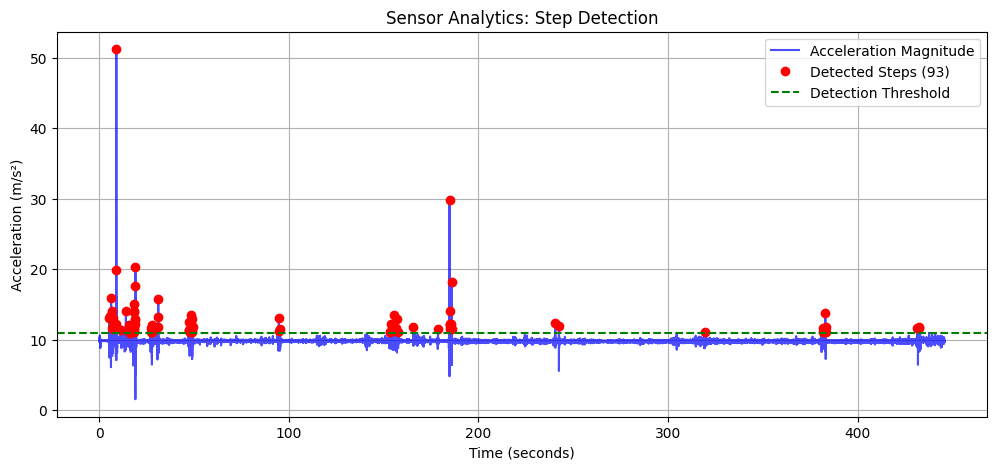

🏃‍♂️ Total Steps Detected: 93
📏 Estimated Distance: 69.75 meters


In [8]:
# CELL 3: DATA PROCESSING & GRAPHING
if latest_data is None:
    print("No data collected. Try running Cell 2 again while walking.")
else:
    # 1. Convert to a Pandas DataFrame
    df = pd.DataFrame(latest_data)
    
    # 2. Calculate Magnitude: ||a|| = sqrt(x^2 + y^2 + z^2)
    df["acc_magnitude"] = np.sqrt(df["acc_x"]**2 + df["acc_y"]**2 + df["acc_z"]**2)
    
    # 3. Find the peaks (steps)
    # We set a threshold just above standard gravity (9.8 + 1.2 = 11.0 m/s^2)
    adaptive_threshold = np.mean(df["acc_magnitude"]) + 1.2
    peaks, _ = find_peaks(df["acc_magnitude"], height=adaptive_threshold, distance=15)
    
    total_steps = len(peaks)
    total_distance = total_steps * STRIDE_LENGTH
    
    # 4. Plot the results!
    plt.figure(figsize=(12, 5))
    plt.plot(df["time"], df["acc_magnitude"], label="Acceleration Magnitude", color="blue", alpha=0.7)
    
    # Mark the detected steps with red dots
    plt.plot(df["time"].iloc[peaks], df["acc_magnitude"].iloc[peaks], "ro", label=f"Detected Steps ({total_steps})")
    
    plt.axhline(y=adaptive_threshold, color='green', linestyle='--', label="Detection Threshold")
    plt.title("Sensor Analytics: Step Detection")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Acceleration (m/s²)")
    plt.legend()
    plt.grid(True)
    plt.show()
    
    print(f"🏃‍♂️ Total Steps Detected: {total_steps}")
    print(f"📏 Estimated Distance: {total_distance:.2f} meters")

In [10]:
# CELL 4: DATA EXPORT
if latest_data is not None:
    # Mark the exact rows where a step occurred
    df["is_step"] = False
    df.loc[peaks, "is_step"] = True

    # Save files
    df.to_csv("my_walking_data.csv", index=False)
    #df.to_excel("my_walking_data.xlsx", index=False, sheet_name="SensorData")

    print("📁 Data successfully saved to your VS Code folder:")
    print(" - my_walking_data.csv")
    #print(" - my_walking_data.xlsx")

📁 Data successfully saved to your VS Code folder:
 - my_walking_data.csv
